In [1]:
import torch
import torch.optim as optim
from torch.utils.data import DataLoader
import numpy as np

from utils.phase import Phase
from utils.model_utils import criterion_to_str
from utils.model_utils import compare_results_strata
from data_augmentation.monte_carlo_loader import MonteCarloLoader
from data_augmentation.datasets.dense_monte_carlo_dataset import DenseMonteCarloDataset
from model.architecture.dense_monte_carlo import DenseMonteCarloNet
from model.architecture.residual_connection_dense import ResDeepAHPNet
from model.loss_function.dense_monte_carlo.custom_dense_MC_loss import CustomDenseMCLoss
from model.model_loader import ModelLoader
from model.trainers.dense_monte_carlo_trainer import DenseMonteCarloTrainer
from analytic_methods.EVM_method import EVM
from visualization.results.metrics_visualizator import MetricsVisualizator
from visualization.data.weights_visualizator import WeightsVisualizator
from metrics.evaluator import Evaluator

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device used: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Device used: cuda
GPU: NVIDIA GeForce RTX 2060


Normalizacja strat względem wartości początkowych (Initial Loss Normalization)
Popularna technika w multi-objective loss polega na przeskalowaniu każdej straty przez jej wartość w pierwszej epoce (lub pierwszym batchu): $$\tilde{L}i = \frac{L_i}{L{i, \text{epoch } 0}}$$ Wtedy każda składowa startuje z poziomu $1.0$, a wagi $\lambda_1, \lambda_2, \lambda_3$ stają się intuicyjnymi, procentowymi wagami ważności celów. 

In [2]:
CRITERIA_NUM = 5
CRITERIA_NUMS = [3, 4, 5, 6, 7, 8, 9]
STRATA = ['low_inconsistency', 'moderate_inconsistency', 'high_inconsistency']
NORMALIZE_INITIAL_LOSS = True # dopisać o tym w pracy 
TRAIN_MATRICES_NUM = None
VALID_MATRICES_NUM = None
TEST_MATRICES_NUM = None

BATCH_SIZE = 1024
LEARNING_RATE = 5e-4
COP = 0.45
FIT = 0.45
STAB = 0.10
P = 1 # 1 = MAE, 2 = MSE
MARGIN = 0.05
EPOCHS = 500
COP_MODE = "margin" 
STAB_MODE = "kullback"
    # COP, FIT, STAB, P, MARGIN, NORMALIZE
PARAMETERS = [
    # [0.5, 0.45, 0.05, 1, 0.05, True, "margin", "kullback"],
    # [0.5, 0.45, 0.05, 1, 0.05, False, "margin", "kullback"],
    # [0.5, 0.45, 0.05, 2, 0.05, False, "margin", "kullback"],
    # [0.7, 0.25, 0.05, 1, 0.05, True, "margin", "kullback"],
    # [0.45, 0.40, 0.15, 1, 0.05, False, "margin", "kullback"],
    # [0.45, 0.40, 0.15, 1, 0.05, True, "margin", "kullback"],
    # [0.7, 0.25, 0.05, 2, 0.05, False, "margin", "kullback"],
    # [0.25, 0.7, 0.05, 2, 0.05, False, "margin", "kullback"],
    [0.25, 0.7, 0.05, 2, 0.05, False, "bradley", "kullback"],
    [0.15, 0.8, 0.05, 2, 0.05, False, "margin", "kullback"],
    [0.5, 0.5, 0, 2, 0.05, False, "margin", "kullback"],
    [0, 0.95, 0.05, 2, 0.05, False, "margin", "kullback"]
]

## Learning All Criterias

In [5]:
# max_train_per_stratum = TRAIN_MATRICES_NUM // len(STRATA) if TRAIN_MATRICES_NUM else None
# max_valid_per_stratum = VALID_MATRICES_NUM // len(STRATA) if VALID_MATRICES_NUM else None

# for criteria_num in CRITERIA_NUMS:
#     train_dataset = DenseMonteCarloDataset(
#         num_criteria=criteria_num,
#         phase=Phase.TRAIN,
#         max_per_stratum=max_train_per_stratum,
#         augment=True
#     )
#     valid_dataset = DenseMonteCarloDataset(
#         num_criteria=criteria_num,
#         phase=Phase.VALIDATION,
#         max_per_stratum=max_valid_per_stratum,
#         augment=False
#     )

#     print(f"Train dataset size: {len(train_dataset)}")
#     print(f"Validation dataset size: {len(valid_dataset)}")

#     model = DenseMonteCarloNet(n_criteria=criteria_num)

#     train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
#     valid_dataloader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)

#     criterion = CustomDenseMCLoss(n_criteria=criteria_num, lambda_cop=COP, lambda_fit=FIT, lambda_stab=STAB, 
#         normalize_initial_loss=NORMALIZE_INITIAL_LOSS).to(device)
#     optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
#     trainer = DenseMonteCarloTrainer(model, optimizer, criterion, device)
#     model, history = trainer.train(train_dataloader, valid_dataloader, epochs=EPOCHS)
#     trainer.save_state_criteria(criteria_num)

## LEARNING PARAMETERS

In [ ]:
max_train_per_stratum = TRAIN_MATRICES_NUM // len(STRATA) if TRAIN_MATRICES_NUM else None
max_valid_per_stratum = VALID_MATRICES_NUM // len(STRATA) if VALID_MATRICES_NUM else None

train_dataset = DenseMonteCarloDataset(
    num_criteria=CRITERIA_NUM,
    phase=Phase.TRAIN,
    max_per_stratum=max_train_per_stratum,
    augment=True
)
valid_dataset = DenseMonteCarloDataset(
    num_criteria=CRITERIA_NUM,
    phase=Phase.VALIDATION,
    max_per_stratum=max_valid_per_stratum,
    augment=False
)

for param in PARAMETERS:
    print(f"Train dataset size: {len(train_dataset)}")
    print(f"Validation dataset size: {len(valid_dataset)}")

    model = DenseMonteCarloNet(n_criteria=CRITERIA_NUM)

    train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    valid_dataloader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)

    criterion = CustomDenseMCLoss(n_criteria=CRITERIA_NUM, lambda_cop=param[0], lambda_fit=param[1], lambda_stab=param[2], 
        p=param[3], margin=param[4], normalize_initial_loss=param[5]).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    trainer = DenseMonteCarloTrainer(model, optimizer, criterion, device)
    model, history = trainer.train(train_dataloader, valid_dataloader, epochs=EPOCHS)
    trainer.save_state_criteria(CRITERIA_NUM)

Train dataset size: 360000
Validation dataset size: 45000


## Dense Monte Carlo Neural Network

In [ ]:
max_train_per_stratum = TRAIN_MATRICES_NUM // len(STRATA) if TRAIN_MATRICES_NUM else None
max_valid_per_stratum = VALID_MATRICES_NUM // len(STRATA) if VALID_MATRICES_NUM else None

train_dataset = DenseMonteCarloDataset(
    num_criteria=CRITERIA_NUM,
    phase=Phase.TRAIN,
    max_per_stratum=max_train_per_stratum,
    augment=True
)
valid_dataset = DenseMonteCarloDataset(
    num_criteria=CRITERIA_NUM,
    phase=Phase.VALIDATION,
    max_per_stratum=max_valid_per_stratum,
    augment=False
)

print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(valid_dataset)}")

Train dataset size: 360000
Validation dataset size: 45000


In [ ]:
model = DenseMonteCarloNet(n_criteria=CRITERIA_NUM)

train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_dataloader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)

criterion = CustomDenseMCLoss(n_criteria=CRITERIA_NUM, lambda_cop=COP, lambda_fit=FIT, lambda_stab=STAB, p=P, 
    normalize_initial_loss=NORMALIZE_INITIAL_LOSS, margin=MARGIN).to(device)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
trainer = DenseMonteCarloTrainer(model, optimizer, criterion, device)
model, history = trainer.train(train_dataloader, valid_dataloader, epochs=EPOCHS)
trainer.save_state_criteria(CRITERIA_NUM)

Initial loss normalization computed over 50 batches:
  COP_0 = 0.959947 | FIT_0 = 1.746305 | STAB_0 = 0.480182
Epoch number [10/500] | Train Loss: 0.247315 | Valid Loss: 0.217457 | Valid MAE: 0.0607
Epoch number [20/500] | Train Loss: 0.242306 | Valid Loss: 0.214524 | Valid MAE: 0.0596
Epoch number [30/500] | Train Loss: 0.239392 | Valid Loss: 0.212921 | Valid MAE: 0.0590
Epoch number [40/500] | Train Loss: 0.237593 | Valid Loss: 0.211711 | Valid MAE: 0.0585
Epoch number [50/500] | Train Loss: 0.236667 | Valid Loss: 0.210834 | Valid MAE: 0.0581
Epoch number [60/500] | Train Loss: 0.236090 | Valid Loss: 0.210752 | Valid MAE: 0.0580
Epoch number [70/500] | Train Loss: 0.235679 | Valid Loss: 0.210199 | Valid MAE: 0.0578
Epoch number [80/500] | Train Loss: 0.235649 | Valid Loss: 0.209805 | Valid MAE: 0.0575
Epoch number 90: Learning Rate was reduced to 0.000250
Epoch number [90/500] | Train Loss: 0.235363 | Valid Loss: 0.209971 | Valid MAE: 0.0576
Epoch number 96: Learning Rate was reduced

In [ ]:
if 'trainer' not in locals():
    criterion = criterion_to_str(COP, FIT, STAB, MARGIN, P, COP_MODE, STAB_MODE, NORMALIZE_INITIAL_LOSS)
    model_loader = ModelLoader()
    model, history = model_loader.load_dense_MC(CRITERIA_NUM, criterion)

In [ ]:
loader = MonteCarloLoader()
max_test_per_stratum = TEST_MATRICES_NUM // len(STRATA) if TEST_MATRICES_NUM else None

matrices = {}
weights = {}
predicted_priority_weights = {}
evm_solver = EVM()
evm_priority_weights = {}

for stratum in STRATA:
    test_mats, test_wts = loader.load_stratum(
        phase=Phase.TEST,
        num_criteria=CRITERIA_NUM,
        stratum=stratum,
        max_count=max_test_per_stratum
    )
    matrices[stratum] = test_mats
    weights[stratum] = test_wts
    predicted_priority_weights[stratum] = trainer.predict_batch(test_mats)
    evm_pw, _ = evm_solver.compute_batch(test_mats)
    evm_priority_weights[stratum] = evm_pw

print("Predicted AHP weights for all strata.")

Predicted AHP weights for all strata.


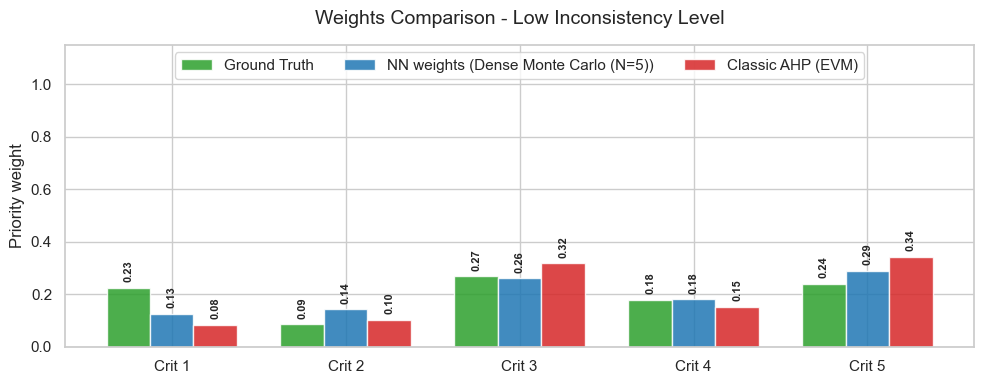

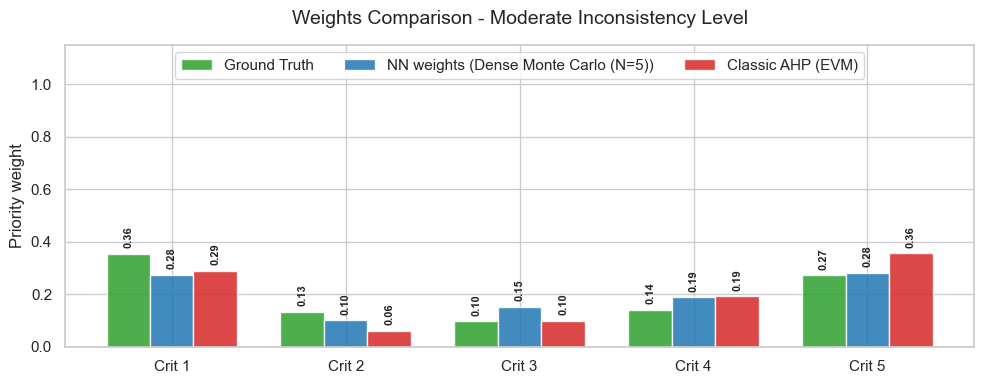

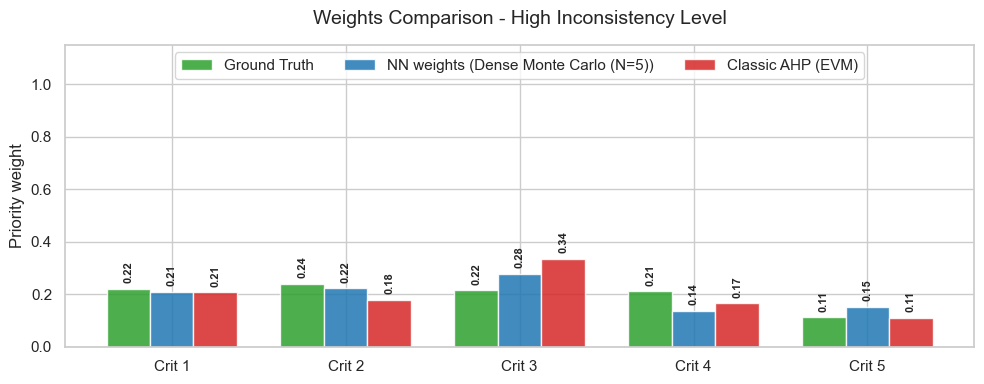

In [ ]:
weights_visualizator = WeightsVisualizator()
nn_name = f"Dense Monte Carlo (N={CRITERIA_NUM})"

for stratum_key in weights.keys():
    pred_weights_vector = predicted_priority_weights[stratum_key][0]
    evm_weights_vector = evm_priority_weights[stratum_key][0].flatten()
    weights_vector = weights[stratum_key][0].flatten()
    weights_visualizator.plot_comparison_all(weights_vector, pred_weights_vector, evm_weights_vector, consistency_level=str(stratum_key).split("_")[0], nn_name=nn_name)

Stratum 'low_inconsistency': Mean CR = 0.0654
  MAE: EVM = 0.0440 | NN = 0.0583
  Kendall Tau: EVM = 0.7392 | NN = 0.7312

Stratum 'moderate_inconsistency': Mean CR = 0.1779
  MAE: EVM = 0.0447 | NN = 0.0565
  Kendall Tau: EVM = 0.7177 | NN = 0.7071

Stratum 'high_inconsistency': Mean CR = 0.4309
  MAE: EVM = 0.0509 | NN = 0.0553
  Kendall Tau: EVM = 0.6278 | NN = 0.6346

--- GLOBAL EXPERIMENT RESULTS ---
Global mean CR: 0.2248
Global mean MAE: EVM = 0.0465, NN = 0.0567
Global mean Kendall Tau: EVM = 0.6949, NN = 0.6910


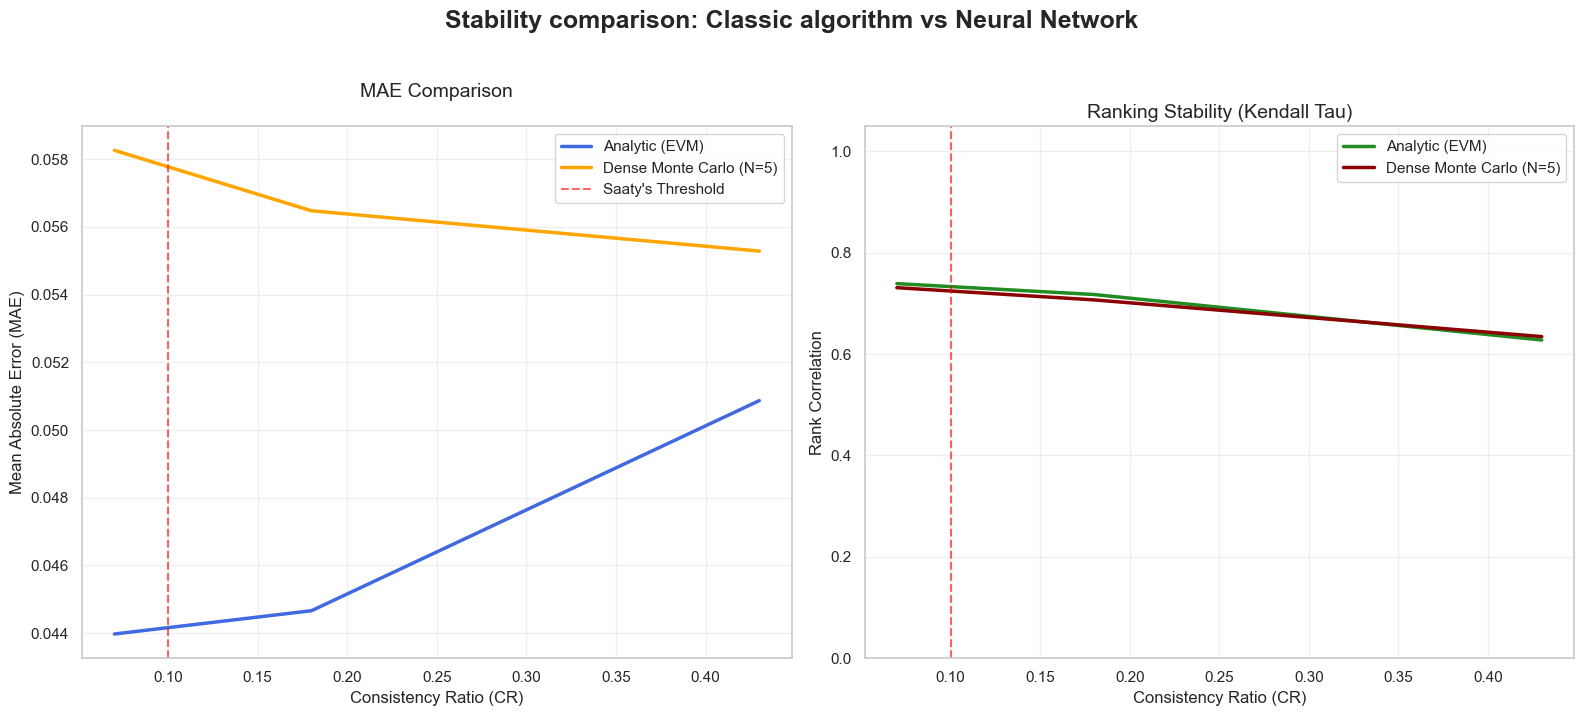

In [ ]:
evm_solver = EVM()
evaluator = Evaluator()
nn_name = f"Dense Monte Carlo (N={CRITERIA_NUM})"

compare_results_strata(evm_solver, evaluator, matrices, weights, predicted_priority_weights, nn_name)

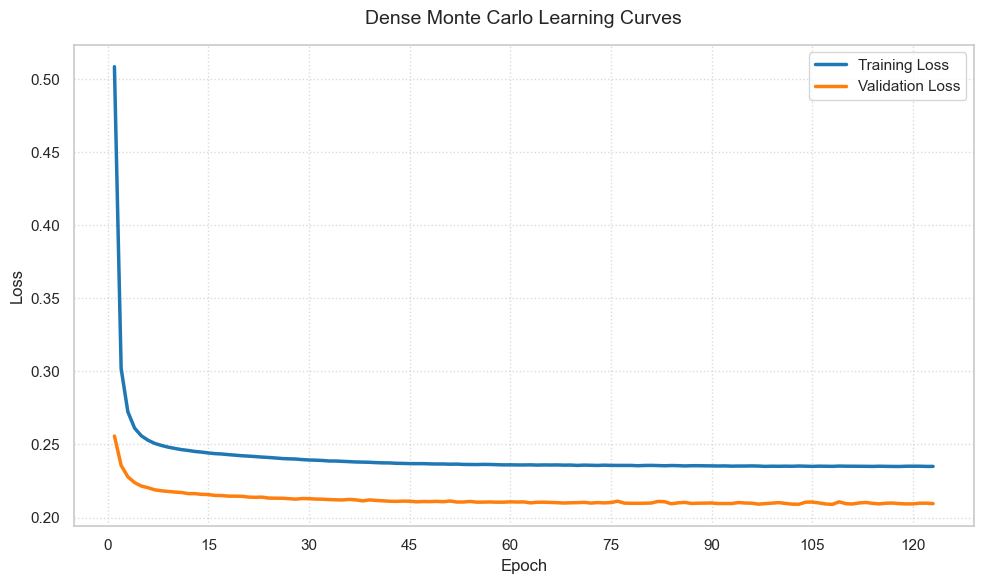

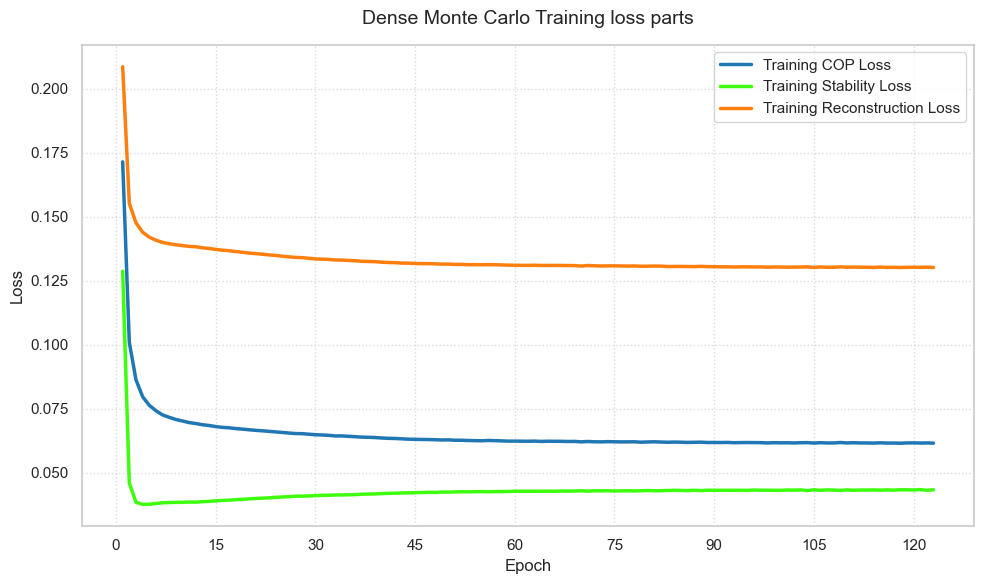

In [ ]:
viz = MetricsVisualizator()
viz.display_loss(history, "Dense Monte Carlo")
viz.display_part_losses(history, "Dense Monte Carlo")

## Loading models

In [ ]:
CRITERIA_NUM = 5
CRITERIA_NUMS = [3, 4, 5, 6, 7, 8, 9]
STRATA = ['low_inconsistency', 'moderate_inconsistency', 'high_inconsistency']
NORMALIZE_INITIAL_LOSS = True # dopisać o tym w pracy 
TRAIN_MATRICES_NUM = None
VALID_MATRICES_NUM = None
TEST_MATRICES_NUM = None

LEARNING_RATE = 5e-4
COP = 0.5
FIT = 0.45
STAB = 0.05
P = 1
MARGIN = 0.05
COP_MODE = "margin" 
STAB_MODE = "kullback"
CRITERION_STR = criterion_to_str(COP, FIT, STAB, MARGIN, P, COP_MODE, STAB_MODE, NORMALIZE_INITIAL_LOSS)

In [ ]:

model_loader = ModelLoader()
empty_model = DenseMonteCarloNet(n_criteria=CRITERIA_NUM)
model, history = model_loader.load_dense_MC(empty_model, CRITERIA_NUM, CRITERION_STR)

criterion = CustomDenseMCLoss(n_criteria=CRITERIA_NUM, lambda_cop=COP, lambda_fit=FIT, lambda_stab=STAB, p=P,
    normalize_initial_loss=NORMALIZE_INITIAL_LOSS).to(device)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
trainer = DenseMonteCarloTrainer(model, optimizer, criterion, device)

loader = MonteCarloLoader()
max_test_per_stratum = TEST_MATRICES_NUM // len(STRATA) if TEST_MATRICES_NUM else None

matrices = {}
weights = {}
predicted_priority_weights = {}
evm_solver = EVM()
evm_priority_weights = {}

for stratum in STRATA:
    test_mats, test_wts = loader.load_stratum(
        phase=Phase.TEST,
        num_criteria=CRITERIA_NUM,
        stratum=stratum,
        max_count=max_test_per_stratum
    )
    matrices[stratum] = test_mats
    weights[stratum] = test_wts
    predicted_priority_weights[stratum] = trainer.predict_batch(test_mats)
    evm_pw, _ = evm_solver.compute_batch(test_mats)
    evm_priority_weights[stratum] = evm_pw

print("Predicted AHP weights for all strata.")

evm_solver = EVM()
evaluator = Evaluator()
nn_name = f"Dense Monte Carlo (N={CRITERIA_NUM})"

compare_results_strata(evm_solver, evaluator, matrices, weights, predicted_priority_weights, nn_name)

FileNotFoundError: There are no files in models\dense_monte_carlo\criteria5 for cop200_fit300_stab50_p1

In [ ]:
CRITERIA_NUM = 5
CRITERIA_NUMS = [3, 4, 5, 6, 7, 8, 9]
STRATA = ['low_inconsistency', 'moderate_inconsistency', 'high_inconsistency']
NORMALIZE_INITIAL_LOSS = True # dopisać o tym w pracy 
TRAIN_MATRICES_NUM = None
VALID_MATRICES_NUM = None
TEST_MATRICES_NUM = None

LEARNING_RATE = 5e-4
COP = 0.5
FIT = 0.45
STAB = 0.05
P = 1
CRITERION_STR = "cop50_fit45_stab5_p1_initnorm"
cop_str = str(int(round(COP * 100)))
fit_str = str(int(round(FIT * 100)))
stab_str = str(int(round(STAB * 100)))
CRITERION_STR = f"cop{cop_str}_fit{fit_str}_stab{stab_str}_p{P}"

History and model: cop50_fit45_stab5_p1_initnorm loaded from models\dense_monte_carlo\criteria5
Predicted AHP weights for all strata.
Stratum 'low_inconsistency': Mean CR = 0.0654
  MAE: EVM = 0.0440 | NN = 0.0469
  Kendall Tau: EVM = 0.7392 | NN = 0.7315

Stratum 'moderate_inconsistency': Mean CR = 0.1779
  MAE: EVM = 0.0447 | NN = 0.0470
  Kendall Tau: EVM = 0.7177 | NN = 0.7043

Stratum 'high_inconsistency': Mean CR = 0.4309
  MAE: EVM = 0.0509 | NN = 0.0494
  Kendall Tau: EVM = 0.6278 | NN = 0.6337

--- GLOBAL EXPERIMENT RESULTS ---
Global mean CR: 0.2248
Global mean MAE: EVM = 0.0465, NN = 0.0478
Global mean Kendall Tau: EVM = 0.6949, NN = 0.6898


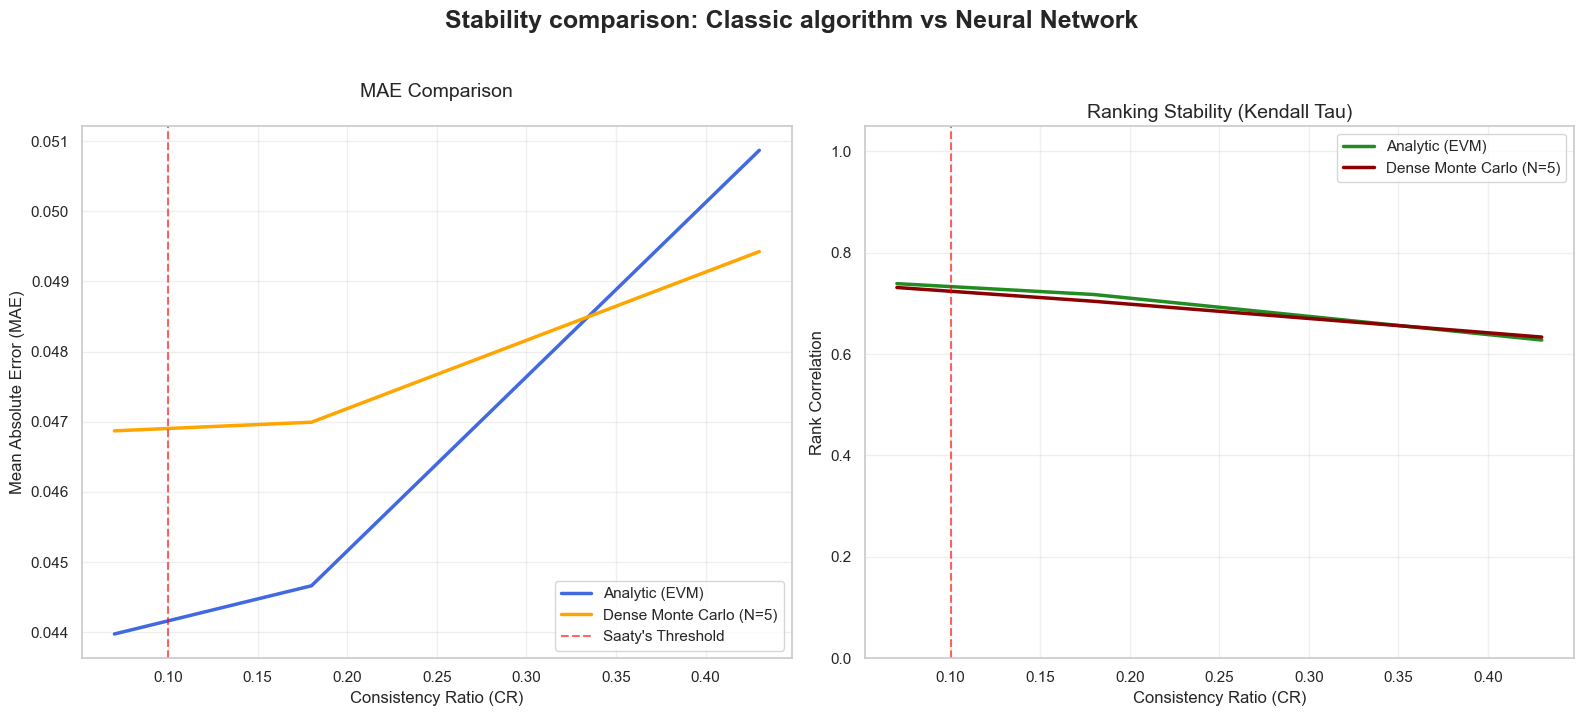

In [ ]:
model_loader = ModelLoader()
empty_model = DenseMonteCarloNet(n_criteria=CRITERIA_NUM)
model, history = model_loader.load_dense_MC(empty_model, CRITERIA_NUM, CRITERION_STR)

criterion = CustomDenseMCLoss(n_criteria=CRITERIA_NUM, lambda_cop=COP, lambda_fit=FIT, lambda_stab=STAB, p=P,
    normalize_initial_loss=NORMALIZE_INITIAL_LOSS).to(device)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
trainer = DenseMonteCarloTrainer(model, optimizer, criterion, device)

loader = MonteCarloLoader()
max_test_per_stratum = TEST_MATRICES_NUM // len(STRATA) if TEST_MATRICES_NUM else None

matrices = {}
weights = {}
predicted_priority_weights = {}
evm_solver = EVM()
evm_priority_weights = {}

for stratum in STRATA:
    test_mats, test_wts = loader.load_stratum(
        phase=Phase.TEST,
        num_criteria=CRITERIA_NUM,
        stratum=stratum,
        max_count=max_test_per_stratum
    )
    matrices[stratum] = test_mats
    weights[stratum] = test_wts
    predicted_priority_weights[stratum] = trainer.predict_batch(test_mats)
    evm_pw, _ = evm_solver.compute_batch(test_mats)
    evm_priority_weights[stratum] = evm_pw

print("Predicted AHP weights for all strata.")

evm_solver = EVM()
evaluator = Evaluator()
nn_name = f"Dense Monte Carlo (N={CRITERIA_NUM})"

compare_results_strata(evm_solver, evaluator, matrices, weights, predicted_priority_weights, nn_name)